# 08 · Processing speed and clicked kits — J3, UD Mansores vs Sanguedo (1080p)

First evaluation of the full-match workflow on `J3_MansoresSanguedo_1080p.mp4` raised three problems:

1. processing a whole match took ~8.5 h (1.8 analysed frames / s);
2. the players clicked in the setup (kits) did not show in the live boxes;
3. the camera-side touchline is often outside the picture.

This notebook measures (1) and (2) with the code of v0.2. (3) is covered by `test_windows_and_near_side_visibility`
and rulebook §3.1. Needs the J3 video, or the extracts `outputs/_seg_J3_2420.mp4` (video 40:20–42:40) and
`outputs/_kitframes/f<frame>.png` (the frames where kits were clicked).

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from football_eval.config import load_config
from football_eval.detection import YoloxOnnxDetector
from football_eval.match_setup import load_setup
from football_eval.teams import KitClassifier, color_descriptor, grass_model, snap_box, torso_crop, person_like, CODE
from football_eval.tracking import iou_matrix
from football_eval.video import iter_frames, probe
VIDEO = ROOT / "data/videos/J3_MansoresSanguedo_1080p.mp4"
SEG = ROOT / "outputs/_seg_J3_2420.mp4"
KF = ROOT / "outputs/_kitframes"
setup = load_setup(ROOT / "configs/match_setup_J3_MansoresSanguedo_1080p.json")
def kit_frame(f):
    p = KF / f"f{f}.png"
    if p.exists():
        return cv2.imread(str(p))
    cap = cv2.VideoCapture(str(VIDEO)); cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, im = cap.read(); cap.release()
    return im if ok else None
seg = SEG if SEG.exists() else VIDEO
seg_t0 = 0.0 if SEG.exists() else 2420.0
print("speed clip:", seg.name, "| kit frames:", sorted({s["frame"] for v in setup["kits"].values() for s in v}))

speed clip: _seg_J3_2420.mp4 | kit frames: [0, 30216, 37259, 60548, 94127]


## 1 · Where the time goes, and what the new tiling buys
The detector is ~95 % of the processing time (decoding ~2 %, camera ~3 %, shirt colours < 1 %). Three settings on
the same 14 frames (one every 10 s): the **previous** layout (6 tiles per 1080p frame, `cv2.dnn`), the new
**standard** (2 pitch-aware tiles, onnxruntime) and the new **quality** preset (800 px tiles).

[detector] YOLOX via cv2.dnn, tiles <= 1024 px (overlap 96)
[detector] YOLOX via onnxruntime/CPUExecutionProvider, tiles <= 1024 px (overlap 96)
[detector] YOLOX via onnxruntime/CPUExecutionProvider, tiles <= 1024 px (overlap 96)
[detector] YOLOX via onnxruntime/CPUExecutionProvider, tiles <= 800 px (overlap 96)


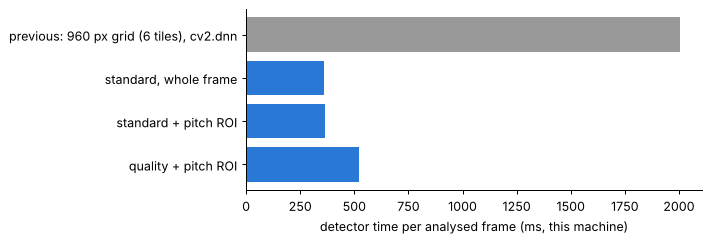

,tiles / frame,ms / frame,players / frame,ball candidates / frame,previous boxes found again,speed-up
"previous: 960 px grid (6 tiles), cv2.dnn",6.0,2006.321,15.143,0.286,212/212,1.0
"standard, whole frame",2.0,359.054,14.5,0.286,200/212,5.6
standard + pitch ROI,2.0,366.503,14.714,0.286,203/212,5.5
quality + pitch ROI,3.0,519.672,15.5,0.429,205/212,3.9


In [2]:
import football_eval.detection as fdet
new_plan = fdet.tile_plan
def legacy_plan(W, H, tile, overlap, roi=None, stretch=1.1):     # v0.1 grid: 960 px tiles, stride 720, whole frame
    T = min(960, H, W)
    ys = sorted(set(list(range(0, max(H - T, 1), 720)) + [H - T])); xs = sorted(set(list(range(0, max(W - T, 1), 720)) + [W - T]))
    return [(x, y, x + T, y + T) for y in ys for x in xs]
M = str(ROOT / "models/yolox.onnx")
ROI = (0, 240, 1920, 1080)        # rows above the far touchline skipped (what the pitch ROI computes on this camera)
dets = {"previous: 960 px grid (6 tiles), cv2.dnn": (YoloxOnnxDetector(M, runtime="cv2"), None, legacy_plan),
        "standard, whole frame": (YoloxOnnxDetector(M, tile=1024, overlap=96), None, new_plan),
        "standard + pitch ROI": (YoloxOnnxDetector(M, tile=1024, overlap=96), ROI, new_plan),
        "quality + pitch ROI": (YoloxOnnxDetector(M, tile=800, overlap=96), ROI, new_plan)}
rows, boxes = {k: [] for k in dets}, {k: [] for k in dets}
for f, t, img in iter_frames(str(seg), 0.1, seg_t0, seg_t0 + 140):
    for k, (D, roi, plan) in dets.items():
        fdet.tile_plan = plan
        t0 = time.perf_counter(); d = D(img, roi=roi); dt = time.perf_counter() - t0
        fdet.tile_plan = new_plan
        rows[k].append((dt, len(d.of("player")), len(d.of("ball")), len(D.last_tiles))); boxes[k].append(d.of("player").xyxy)
ref = list(dets)[0]
res = {}
for k in dets:
    a = np.array(rows[k])
    found = sum(int((iou_matrix(b0, b1).max(1) > 0.5).sum()) if len(b1) and len(b0) else 0 for b0, b1 in zip(boxes[ref], boxes[k]))
    res[k] = {"tiles / frame": a[:, 3].mean(), "ms / frame": 1000 * a[:, 0].mean(), "players / frame": a[:, 1].mean(),
              "ball candidates / frame": a[:, 2].mean(), "previous boxes found again": f"{found}/{sum(len(b) for b in boxes[ref])}"}
R = pd.DataFrame(res).T
R["speed-up"] = (R["ms / frame"].iloc[0] / R["ms / frame"]).round(1)
fig, ax = plt.subplots(figsize=(8, 2.8)); ax.barh(R.index[::-1], R["ms / frame"][::-1], color=["#2a78d6"] * (len(R) - 1) + ["#999"])
ax.set_xlabel("detector time per analysed frame (ms, this machine)"); plt.tight_layout()
R.round(2)

**Verdict:** the previous grid ran two rows of tiles only 120 px apart on a 1080-px frame. Two tiles that just cover
the pitch, plus onnxruntime, make the detector ~5× faster. The price is resolution: a 1008-px wide tile is shrunk
to the 640-px network input (0.63×, was 0.67×), so a few distant players and ball candidates are lost — the pitch ROI
(skipping the sky and stands) gets part of it back. *Quality* (800-px tiles) is still ~2× faster than before. On the Mac, onnxruntime also tries the CoreML provider and keeps it only if it is faster. Full match at
10 analysed fps ≈ 54k frames: the launcher estimates the time from the speed measured by your previous runs.

## 2 · The boxes you dragged vs the player the detector sees
The kit descriptor looks at the shirt (20–80 % of the box width, 15–55 % of its height). A loose box puts grass —
or a neighbour — in that window.

53 clicked samples on 5 moments; snapped: 51
IoU of the drawn box with the detected player: {'min': 0.0, '25%': 0.42, '50%': 0.5, '75%': 0.66, 'max': 0.95}


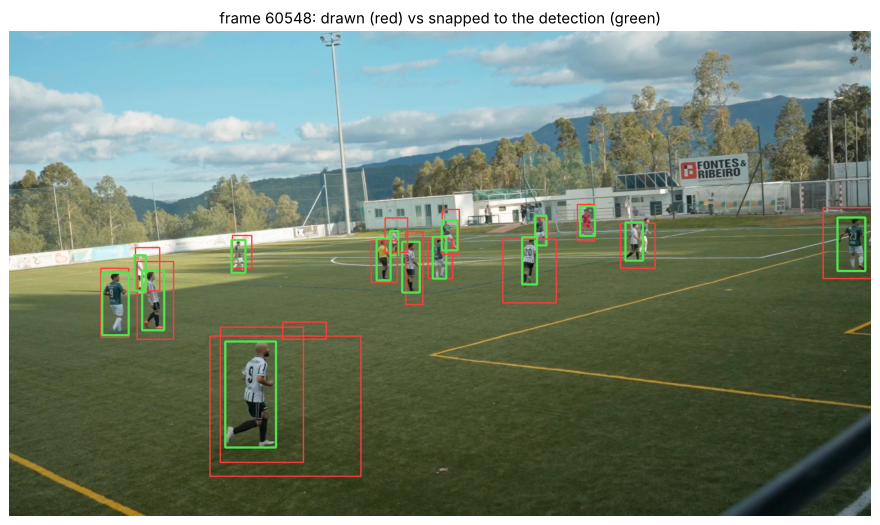

In [3]:
det = dets["standard, whole frame"][0]
S, frames = [], {}
for cls, items in setup["kits"].items():
    for it in items:
        f = it["frame"]
        if f not in frames:
            frames[f] = kit_frame(f)
        img = frames[f]
        if img is None: continue
        P = det(img).of("player").xyxy
        sb = snap_box(it["box"], P)
        iou = float(iou_matrix(np.array([it["box"]], float), P).max()) if len(P) else 0.0
        S.append(dict(cls=cls, frame=f, drawn=np.array(it["box"], float), snapped=sb, iou_with_detection=iou))
K = pd.DataFrame(S)
print(f"{len(K)} clicked samples on {K.frame.nunique()} moments; snapped: {K.snapped.notna().sum()}")
print("IoU of the drawn box with the detected player:", K.iou_with_detection.describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_dict())
f0 = 60548 if 60548 in frames else list(frames)[0]
vis = frames[f0].copy()
for _, r in K[K.frame == f0].iterrows():
    x0, y0, x1, y1 = r.drawn.astype(int); cv2.rectangle(vis, (x0, y0), (x1, y1), (60, 60, 255), 2)
    if r.snapped is not None:
        x0, y0, x1, y1 = np.asarray(r.snapped).astype(int); cv2.rectangle(vis, (x0, y0), (x1, y1), (80, 230, 80), 3)
plt.figure(figsize=(13, 7)); plt.imshow(vis[..., ::-1]); plt.axis("off"); plt.title(f"frame {f0}: drawn (red) vs snapped to the detection (green)");

## 3 · Can the clicked samples recognise each other?
**Leave-one-out**: each clicked sample is classified by all the others (same rule as the pipeline: mean distance to
the 2 nearest samples of each class). **Leave-one-moment-out**: all samples of one moment are classified by the
samples of the other moments (new lighting / camera position) — the realistic case. Three variants: the drawn boxes
with the previous descriptor (fixed green band removed as "grass"), the snapped boxes with that descriptor, and the
snapped boxes with the v0.2 descriptor (only *this frame's* pitch colour removed, no lightness).

In [4]:
def legacy_descriptor(crop):                     # v0.1: fixed hue band 30-90 removed as grass, Lab quartiles
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    keep = ~((hsv[..., 0] > 30) & (hsv[..., 0] < 90) & (hsv[..., 1] > 50) & (hsv[..., 2] > 40))
    if keep.sum() < 6: return None
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB)[keep].astype(float)
    q = np.percentile(lab, [25, 50, 75], axis=0).ravel() / 255.0
    hist, _ = np.histogram(hsv[..., 0][keep], bins=12, range=(0, 180), weights=hsv[..., 1][keep] / 255.0 + 0.05)
    br = np.array([(hsv[..., 2][keep] > 170).mean(), (hsv[..., 2][keep] < 60).mean()])
    return np.r_[2.0 * q, hist / (hist.sum() + 1e-9), br]
def describe(r, which):
    img = frames[r.frame]
    box = r.drawn if which == "drawn" else r.snapped
    if box is None: return None
    c = torso_crop(img, box)
    if c is None: return None
    return legacy_descriptor(c) if which != "new" else color_descriptor(c, grass_model(img))
def evaluate(which):
    use = K if which == "drawn" else K[K.snapped.notna()]
    D = [(r.cls, r.frame, describe(r, "drawn" if which == "drawn" else ("new" if which == "new" else "snapped"))) for _, r in use.iterrows()]
    D = [d for d in D if d[2] is not None]
    out = {}
    for name, split in (("leave-one-out", lambda i, j: i != j), ("leave-one-moment-out", lambda i, j: D[i][1] != D[j][1])):
        ok_out = ok_all = n_out = n_all = 0
        for i, (c, f, d) in enumerate(D):
            samples = {}
            for j, (c2, f2, d2) in enumerate(D):
                if split(i, j): samples.setdefault(c2, []).append(d2)
            if "team0" not in samples or "team1" not in samples or c not in samples: continue
            p = KitClassifier(samples).predict(np.array([d]))[0]
            hit = p == CODE[c]; n_all += 1; ok_all += hit
            if c in ("team0", "team1"): n_out += 1; ok_out += hit
        out[name + " (outfield)"] = f"{ok_out}/{n_out}"; out[name + " (all classes)"] = f"{ok_all}/{n_all}"
    return out
pd.DataFrame({"drawn boxes, previous descriptor": evaluate("drawn"),
              "snapped boxes, previous descriptor": evaluate("snapped"),
              "snapped boxes, v0.2 descriptor": evaluate("new")}).T

,leave-one-out (outfield),leave-one-out (all classes),leave-one-moment-out (outfield),leave-one-moment-out (all classes)
"drawn boxes, previous descriptor",25/46,29/51,28/46,32/51
"snapped boxes, previous descriptor",35/45,39/50,31/45,36/50
"snapped boxes, v0.2 descriptor",44/45,49/50,40/45,45/50


**Verdict:** both problems were in the input, not in the voting: loose boxes (grass in the shirt window) and a
"grass" mask that also deleted the green UD Mansores shirts. With snapped boxes and the per-frame pitch colour the
clicked samples recognise each other almost perfectly, also across moments. A class with a single sample (the
Sanguedo goalkeeper) cannot be checked by leave-one-out — click it on 2–3 moments.

The same classifier now drives the live boxes and the final team assignment; the tracks you clicked keep your
label (`team_assignment.csv`, column `clicked`).